# 07 — Comparison of the four candidates and recommendation (N6, N7 robustness)

Each family froze **one** candidate on validation: classical (`04`), feed-forward network (`03`, Anthony), frozen ResNet18 (`05`), fine-tuned ResNet18 (`06`). This notebook scores them **together, once**, and checks them against the decision criteria fixed in PLAN §4 before any result:

1. **Accuracy**: test top-1 ≥ 85 % **and** significantly better than the classical model (exact McNemar, p < 0.05).
2. **Latency**: 1-thread CPU median ≤ 40 ms (= 200 ms kiosk budget / ×5 safety factor, an assumption).
3. **Footprint**: ≤ 100 MB on disk, trainable in < 1 hour on a laptop.

**Recommendation = the cheapest candidate meeting all three** (order of cost: classical < FFN < frozen ResNet < fine-tuned ResNet).

> **Two modes.** By default this notebook runs as a **rehearsal on the validation set**, so the code, tables and figures can be checked without touching the test set. Validation numbers are optimistic (every candidate was selected on them). The real run is done once, together, with
> `FINAL_TEST=1 jupyter nbconvert --to notebook --execute --inplace notebooks/07_comparison.ipynb`
> which scores the test set and adds the test fields to `results/*.json`.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch  # imported before scikit-learn: see tests/conftest.py

FINAL_TEST = os.environ.get("FINAL_TEST") == "1"
FAST_RUN = os.environ.get("FAST_RUN") == "1"
EVAL = "test" if FINAL_TEST else "val"
FIG, CKPT = "../results/figures", "../checkpoints"
torch.manual_seed(0)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "axes.axisbelow": True, "lines.linewidth": 2,
                     "font.size": 10, "axes.titlesize": 11, "legend.frameon": False})
print(f"Evaluating on: {EVAL.upper()}" + ("" if FINAL_TEST else "  (REHEARSAL — not the final result)"))

Evaluating on: TEST


In [2]:
import pickle
import sys

sys.path.insert(0, "../src")
from museum.data import CLASSES, IMAGENET_MEAN, IMAGENET_STD, get_arrays, load_split
from museum.evaluation import accuracy_report, holm, load_results, mcnemar, plot_confusion, save_result, wilson_ci
from museum.models import FFN_CANDIDATE, StyleMLP, TorchPredictor, build_resnet18
from museum.train import get_device

device = get_device()
results = load_results()
X_val, y_val = get_arrays(128, "val")
X_eval, y_eval = get_arrays(128, EVAL)
eval_paths = load_split().query("split == @EVAL").path.to_numpy()
print(f"{len(y_eval)} {EVAL} images; result files: {sorted(results)}")

225 test images; result files: ['classical', 'ffn', 'resnet_finetune', 'resnet_frozen']


## 1. Loading the frozen candidates

Every candidate takes the same input, raw 128 px RGB images, and does its own preprocessing (that is also what its latency measures).

**FFN checkpoint** (written by `03`, section 9): `checkpoints/ffn.pt` = `{"state_dict", "config", "recipe", "mean", "std"}`, rebuilt with `StyleMLP(**config)`; `config` must equal `FFN_CANDIDATE`. In the rehearsal, a candidate whose checkpoint or `results/<name>.json` is missing is skipped and the rest still runs; **the final test run refuses to start unless all four are loaded.**

**Integrity check:** each loaded checkpoint must reproduce, on validation, the accuracy recorded in its `results/<name>.json` when it was frozen. This proves we score the frozen candidates and not a re-trained or stale model.

In [3]:
ORDER = ["classical", "ffn", "resnet_frozen", "resnet_finetune"]
LABELS = {"classical": "Classical (HSV + HOG)", "ffn": "Feed-forward net",
          "resnet_frozen": "ResNet18 frozen", "resnet_finetune": "ResNet18 fine-tuned"}
COLORS = {"classical": "#2a78d6", "ffn": "#eb6834", "resnet_frozen": "#1baf7a", "resnet_finetune": "#eda100"}


class SklearnModel:
    def __init__(self, pipe):
        self.pipe = pipe

    def predict(self, images):
        return self.pipe.predict(images)


def load_candidate(name):
    if name == "classical":
        with open(f"{CKPT}/classical.pkl", "rb") as handle:
            return SklearnModel(pickle.load(handle))
    ckpt = torch.load(f"{CKPT}/{name}.pt", map_location="cpu")
    if name == "ffn":
        assert ckpt["config"] == FFN_CANDIDATE, "checkpoints/ffn.pt is not the frozen FFN candidate"
        model = StyleMLP(**ckpt["config"])
        img_size, mean, std = ckpt["config"]["img_size"], ckpt["mean"], ckpt["std"]
    else:
        model = build_resnet18(pretrained=False, trainable=ckpt["trainable"])
        img_size, (mean, std) = ckpt["img_size"], (IMAGENET_MEAN, IMAGENET_STD)
    model.load_state_dict(ckpt["state_dict"])
    return TorchPredictor(model, img_size, mean, std, device=device)


candidates = {}
for name in ORDER:
    if name not in results:
        print(f"skipped {name}: results/{name}.json is missing")
        continue
    try:
        candidates[name] = load_candidate(name)
    except FileNotFoundError as err:
        print(f"skipped {name}: {err}")
        continue
    reproduced = float((candidates[name].predict(X_val) == y_val).mean())
    assert abs(reproduced - results[name]["val_acc"]) < 1e-9, \
        f"{name}: checkpoint gives val acc {reproduced:.4f}, results/{name}.json says {results[name]['val_acc']:.4f}"
    print(f"loaded {name}: val acc {reproduced:.3f}, as recorded when it was frozen")
NAMES = list(candidates)
assert "classical" in NAMES, "the classical baseline is the reference of criterion 1"
if FINAL_TEST:
    assert NAMES == ORDER, f"the test set is scored once, with all four candidates; missing {set(ORDER) - set(NAMES)}"

loaded classical: val acc 0.551, as recorded when it was frozen


loaded ffn: val acc 0.458, as recorded when it was frozen


loaded resnet_frozen: val acc 0.840, as recorded when it was frozen


loaded resnet_finetune: val acc 0.862, as recorded when it was frozen


## 2. Scores

In [4]:
preds = {name: model.predict(X_eval) for name, model in candidates.items()}
rows = []
for name in NAMES:
    report, res = accuracy_report(y_eval, preds[name]), results[name]
    rows.append({"model": LABELS[name], "accuracy": report["test_acc"],
                 "95% CI": f"[{report['test_ci'][0]:.3f}, {report['test_ci'][1]:.3f}]",
                 "macro-F1": report["macro_f1"], "val acc (selection)": res["val_acc"],
                 "latency 1 thread (ms)": res["latency_ms"]["threads_1"]["median_ms"],
                 "p95 1 thread (ms)": res["latency_ms"]["threads_1"]["p95_ms"],
                 "latency 2 threads (ms)": res["latency_ms"]["threads_2"]["median_ms"],
                 "size (MB)": res["size_mb"], "parameters": res["n_params"], "train time (s)": res["train_time_s"]})
table = pd.DataFrame(rows).set_index("model")
table.style.format({"accuracy": "{:.3f}", "macro-F1": "{:.3f}", "val acc (selection)": "{:.3f}",
                    "latency 1 thread (ms)": "{:.2f}", "p95 1 thread (ms)": "{:.2f}",
                    "latency 2 threads (ms)": "{:.2f}", "size (MB)": "{:.1f}", "parameters": "{:,}",
                    "train time (s)": "{:.0f}"})

,accuracy,95% CI,macro-F1,val acc (selection),latency 1 thread (ms),p95 1 thread (ms),latency 2 threads (ms),size (MB),parameters,train time (s)
model,,,,,,,,,,
Classical (HSV + HOG),0.476,"[0.411, 0.541]",0.475,0.551,2.98,3.11,2.97,16.5,"2,058,002",3
Feed-forward net,0.404,"[0.342, 0.470]",0.395,0.458,0.09,0.10,0.08,3.3,"820,229",4
ResNet18 frozen,0.796,"[0.738, 0.843]",0.795,0.840,19.08,30.22,14.47,44.8,"11,179,077",4
ResNet18 fine-tuned,0.840,"[0.786, 0.882]",0.838,0.862,16.62,17.78,14.35,44.8,"11,179,077",78


## 3. Are the differences significant? Pairwise exact McNemar

McNemar only looks at the images where two models disagree (one right, one wrong). We report the raw p-values (the criterion fixed in advance) and the Holm-adjusted ones, which control the error over all the pairs tested at once.

In [5]:
pairs = [(a, b) for k, a in enumerate(NAMES) for b in NAMES[k + 1:]]
raw = {(a, b): mcnemar(y_eval, preds[a], preds[b]) for a, b in pairs}
adj = holm(raw) if raw else {}
mc = pd.DataFrame([{"A": LABELS[a], "B": LABELS[b],
                    "A right, B wrong": int(((preds[a] == y_eval) & (preds[b] != y_eval)).sum()),
                    "A wrong, B right": int(((preds[a] != y_eval) & (preds[b] == y_eval)).sum()),
                    "p (exact)": raw[(a, b)], "p (Holm)": adj[(a, b)]} for a, b in pairs])
mc.style.format({"p (exact)": "{:.4f}", "p (Holm)": "{:.4f}"})

,A,B,"A right, B wrong","A wrong, B right",p (exact),p (Holm)
0,Classical (HSV + HOG),Feed-forward net,53,37,0.1133,0.1510
1,Classical (HSV + HOG),ResNet18 frozen,13,85,0.0000,0.0000
2,Classical (HSV + HOG),ResNet18 fine-tuned,6,88,0.0000,0.0000
3,Feed-forward net,ResNet18 frozen,14,102,0.0000,0.0000
4,Feed-forward net,ResNet18 fine-tuned,6,104,0.0000,0.0000
5,ResNet18 frozen,ResNet18 fine-tuned,8,18,0.0755,0.1510


## 4. Decision criteria and recommendation

In [6]:
COST_ORDER = [n for n in ORDER if n in NAMES]
checks = []
for name in COST_ORDER:
    acc, res = (preds[name] == y_eval).mean(), results[name]
    p = 0.0 if name == "classical" else raw[("classical", name)]
    better = name == "classical" or (p < 0.05 and acc > (preds["classical"] == y_eval).mean())
    lat = res["latency_ms"]["threads_1"]["median_ms"]
    checks.append({"model": LABELS[name], "acc ≥ 85 %": acc >= 0.85, "beats classical (p<0.05)": better,
                   "latency ≤ 40 ms": lat <= 40, "size ≤ 100 MB": res["size_mb"] <= 100,
                   "train < 1 h": res["train_time_s"] < 3600, "_name": name, "_acc": acc, "_lat": lat, "_p": p})
checks = pd.DataFrame(checks)
crit = ["acc ≥ 85 %", "beats classical (p<0.05)", "latency ≤ 40 ms", "size ≤ 100 MB", "train < 1 h"]
checks["passes all"] = checks[crit].all(axis=1)
shown = checks.set_index("model")[crit + ["passes all"]].replace({True: "yes", False: "NO"})
shown.loc[LABELS["classical"], "beats classical (p<0.05)"] = "n/a"  # the baseline is the reference
print(shown.to_string())

passing = checks[checks["passes all"]]
print()
if len(passing):
    pick = passing.iloc[0]
    print(f"RECOMMENDATION ({EVAL}): {pick.model} — the cheapest candidate meeting every criterion "
          f"(accuracy {pick._acc:.1%}, {pick._lat:.1f} ms on 1 CPU thread).")
else:
    best = checks.sort_values("_acc").iloc[-1]
    failed = [c for c in crit if not best[c]]
    print(f"No candidate meets every criterion. Most accurate: {best.model} ({best._acc:.1%}); it fails: {failed}.")
if not FINAL_TEST:
    print("Rehearsal on validation only: the final recommendation comes from the FINAL_TEST=1 run.")

                      acc ≥ 85 % beats classical (p<0.05) latency ≤ 40 ms size ≤ 100 MB train < 1 h passes all
model                                                                                                         
Classical (HSV + HOG)         NO                      n/a             yes           yes         yes         NO
Feed-forward net              NO                       NO             yes           yes         yes         NO
ResNet18 frozen               NO                      yes             yes           yes         yes         NO
ResNet18 fine-tuned           NO                      yes             yes           yes         yes         NO

No candidate meets every criterion. Most accurate: ResNet18 fine-tuned (84.0%); it fails: ['acc ≥ 85 %'].


## 5. Accuracy vs CPU cost (Pareto)

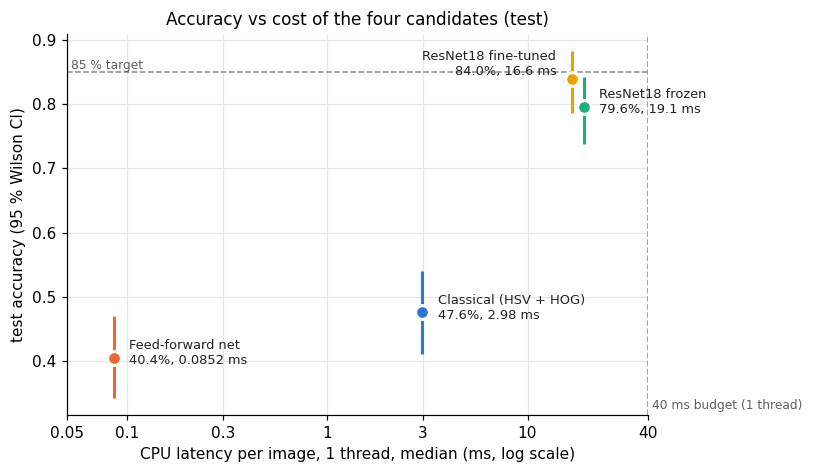

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4.4))
# The two ResNets sit close together: one label on each side of its point.
LABEL_POS = {"resnet_finetune": ((-10, 2), "right")}
for name in NAMES:
    k = int((preds[name] == y_eval).sum())
    low, high = wilson_ci(k, len(y_eval))
    lat = results[name]["latency_ms"]["threads_1"]["median_ms"]
    acc = k / len(y_eval)
    ax.errorbar(lat, acc, yerr=[[acc - low], [high - acc]], fmt="o", markersize=9, color=COLORS[name],
                ecolor=COLORS[name], elinewidth=2, capsize=0, markeredgecolor="white", markeredgewidth=2, zorder=3)
    offset, align = LABEL_POS.get(name, ((10, -4), "left"))
    ax.annotate(f"{LABELS[name]}\n{acc:.1%}, {lat:.3g} ms", (lat, acc), xytext=offset, textcoords="offset points",
                ha=align, fontsize=8.5, color="#1f2328")
ax.set_xscale("log")
ax.set_xticks([0.05, 0.1, 0.3, 1, 3, 10, 40], ["0.05", "0.1", "0.3", "1", "3", "10", "40"])
ax.minorticks_off()
ax.axvline(40, color="#8a8a85", linestyle="--", linewidth=1)
ax.axhline(0.85, color="#8a8a85", linestyle="--", linewidth=1)
ax.text(40 * 1.05, ax.get_ylim()[0] + 0.01, "40 ms budget (1 thread)", fontsize=8, color="#5f5f5a")
ax.text(ax.get_xlim()[0] * 1.05, 0.855, "85 % target", fontsize=8, color="#5f5f5a")
ax.set_xlabel("CPU latency per image, 1 thread, median (ms, log scale)")
ax.set_ylabel(f"{EVAL} accuracy (95 % Wilson CI)")
ax.set_title(f"Accuracy vs cost of the four candidates ({EVAL})")
fig.tight_layout()
fig.savefig(f"{FIG}/comparison_pareto_{EVAL}.png", bbox_inches="tight")
plt.show()

In [8]:
for name in NAMES:
    plot_confusion(y_eval, preds[name], CLASSES, f"{FIG}/comparison_confusion_{name}_{EVAL}.png",
                   title=f"{LABELS[name]} ({EVAL})")
per_class = pd.DataFrame({LABELS[n]: [(preds[n][y_eval == k] == k).mean() for k in range(5)] for n in NAMES},
                         index=CLASSES)
per_class.style.format("{:.2f}").set_caption(f"Recall per style ({EVAL})")

,Classical (HSV + HOG),Feed-forward net,ResNet18 frozen,ResNet18 fine-tuned
Baroque,0.49,0.56,0.71,0.76
Cubism,0.38,0.18,0.82,0.82
Impressionism,0.36,0.38,0.82,0.91
Pop_Art,0.60,0.38,0.71,0.76
Ukiyo_e,0.56,0.53,0.91,0.96


## 6. Leakage sensitivity: without the near-duplicates

`05` flagged the pairs of images whose ResNet features have cosine similarity > 0.95. If an evaluated image has such a twin in the training set, a model can be "right" by memory. We recompute the accuracy without those images.

In [9]:
dups = pd.read_csv("../results/near_duplicates.csv")
twin = set(dups.loc[(dups.split_a == "train") & (dups.split_b == EVAL), "path_b"]) | \
       set(dups.loc[(dups.split_b == "train") & (dups.split_a == EVAL), "path_a"])
keep = ~np.isin(eval_paths, list(twin))
print(f"{(~keep).sum()} of {len(keep)} {EVAL} images have a near-duplicate in train")
pd.DataFrame({"all images": [(preds[n] == y_eval).mean() for n in NAMES],
              "without near-duplicates": [(preds[n][keep] == y_eval[keep]).mean() for n in NAMES]},
             index=[LABELS[n] for n in NAMES]).style.format("{:.3f}")

0 of 225 test images have a near-duplicate in train


,all images,without near-duplicates
Classical (HSV + HOG),0.476,0.476
Feed-forward net,0.404,0.404
ResNet18 frozen,0.796,0.796
ResNet18 fine-tuned,0.840,0.840


## 7. Camera robustness (N7)

On a kiosk the image comes from a camera, not a clean scan. We simulate 5 perturbations on the evaluated images and measure the accuracy of each model (same images, same perturbation for every model, fixed seed):
- **blur**: Gaussian blur, radius 1.5 px (out of focus / motion);
- **darker / brighter**: brightness × 0.6 / × 1.4 (gallery lighting);
- **crop**: central 75 % of the image, resized back (the visitor frames only part of the painting);
- **perspective**: random perspective distortion of up to 30 % (photo taken at an angle).

In [10]:
from PIL import Image, ImageEnhance, ImageFilter
from torchvision.transforms import v2


def perturb(images, kind, seed=0):
    torch.manual_seed(seed)
    persp = v2.RandomPerspective(distortion_scale=0.3, p=1.0)
    out = []
    for im in images:
        pil = Image.fromarray(im)
        if kind == "blur":
            pil = pil.filter(ImageFilter.GaussianBlur(1.5))
        elif kind in ("darker", "brighter"):
            pil = ImageEnhance.Brightness(pil).enhance(0.6 if kind == "darker" else 1.4)
        elif kind == "crop":
            m = round(pil.width * 0.125)
            pil = pil.crop((m, m, pil.width - m, pil.height - m)).resize(im.shape[:2][::-1], Image.Resampling.BILINEAR)
        elif kind == "perspective":
            pil = persp(pil)
        out.append(np.asarray(pil))
    return np.stack(out)


KINDS = ["clean", "blur", "darker", "brighter", "crop", "perspective"]
robust = {}
for kind in KINDS:
    X_k = X_eval if kind == "clean" else perturb(X_eval, kind)
    robust[kind] = {n: float((candidates[n].predict(X_k) == y_eval).mean()) for n in NAMES}
robust = pd.DataFrame(robust).T.rename(columns=LABELS)
robust.round(3).to_csv(f"../results/robustness_{EVAL}.csv")
drop = (robust - robust.loc["clean"]).drop(index="clean")
robust.style.format("{:.3f}").set_caption(f"Accuracy under perturbation ({EVAL})")

,Classical (HSV + HOG),Feed-forward net,ResNet18 frozen,ResNet18 fine-tuned
clean,0.476,0.404,0.796,0.840
blur,0.462,0.400,0.596,0.689
darker,0.489,0.267,0.733,0.813
brighter,0.449,0.347,0.733,0.787
crop,0.404,0.382,0.751,0.804
perspective,0.311,0.249,0.631,0.756


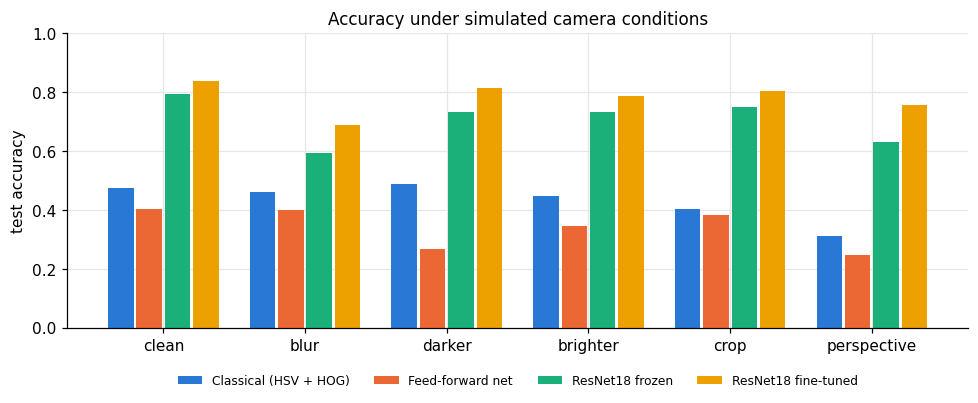

,Classical (HSV + HOG),Feed-forward net,ResNet18 frozen,ResNet18 fine-tuned
blur,-0.013,-0.004,-0.200,-0.151
darker,+0.013,-0.138,-0.062,-0.027
brighter,-0.027,-0.058,-0.062,-0.053
crop,-0.071,-0.022,-0.044,-0.036
perspective,-0.164,-0.156,-0.164,-0.084


In [11]:
fig, ax = plt.subplots(figsize=(9, 3.8))
width = 0.8 / len(NAMES)
for k, name in enumerate(NAMES):
    xs = np.arange(len(KINDS)) + (k - (len(NAMES) - 1) / 2) * width
    ax.bar(xs, robust[LABELS[name]], width=width - 0.02, color=COLORS[name], label=LABELS[name])
ax.set_xticks(np.arange(len(KINDS)), KINDS)
ax.set_ylim(0, 1)
ax.set_ylabel(f"{EVAL} accuracy")
ax.set_title("Accuracy under simulated camera conditions")
ax.legend(ncols=len(NAMES), fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
fig.savefig(f"{FIG}/comparison_robustness_{EVAL}.png", bbox_inches="tight")
plt.show()
drop.style.format("{:+.3f}").set_caption("Change vs clean images")

## 8. Writing the test results (final run only)

In [12]:
if FINAL_TEST:
    for name in NAMES:
        print("wrote", save_result(name, accuracy_report(y_eval, preds[name])))
else:
    print("Rehearsal: nothing written. Run with FINAL_TEST=1, once, together, to record the test results.")

wrote /Users/mactonio/Desktop/Albert School/Year 2/S1/Neural Networks & Deep Learning Foundations/Final Project/Neural-Network-Project-n4/results/classical.json
wrote /Users/mactonio/Desktop/Albert School/Year 2/S1/Neural Networks & Deep Learning Foundations/Final Project/Neural-Network-Project-n4/results/ffn.json
wrote /Users/mactonio/Desktop/Albert School/Year 2/S1/Neural Networks & Deep Learning Foundations/Final Project/Neural-Network-Project-n4/results/resnet_frozen.json
wrote /Users/mactonio/Desktop/Albert School/Year 2/S1/Neural Networks & Deep Learning Foundations/Final Project/Neural-Network-Project-n4/results/resnet_finetune.json


## 9. Conclusion (final test run)

**No candidate meets all three criteria fixed in PLAN §4.** As planned for that case, we name the criterion that fails and by how much.

| | Test acc. (95 % CI) | Beats classical | Latency, 1 thread | Size | Train time | Passes all |
|---|---|---|---|---|---|---|
| Classical (HSV + HOG) | 47.6 % [41.1, 54.1] | reference | 3.0 ms | 16.5 MB | 3 s | no (accuracy) |
| Feed-forward net | 40.4 % [34.2, 47.0] | no (p = 0.11) | 0.09 ms | 3.3 MB | 4 s | no (accuracy) |
| ResNet18 frozen | 79.6 % [73.8, 84.3] | yes (p < 0.001) | 19.1 ms | 44.8 MB | 4 s | no (accuracy) |
| **ResNet18 fine-tuned** | **84.0 % [78.6, 88.2]** | yes (p < 0.001) | 16.6 ms | 44.8 MB | 78 s | no (accuracy) |

- **The fine-tuned ResNet18 comes closest.** It passes latency, footprint and the significance test, and misses the 85 % accuracy bar by **1.0 point**: 189 of 225 test images right, where 85 % needs 192, so 3 images short. The 95 % CI [78.6, 88.2] contains 85 %, so the test set cannot tell whether it is truly above or below the bar.
- **Validation was slightly optimistic**, as expected after selecting on it: 86.2 % on val became 84.0 % on test (frozen: 84.0 % became 79.6 %). Nothing was re-tuned after seeing the test set.
- **Pretraining is what matters.** Both ResNets beat the classical model and the FFN by about 35–45 points (p < 0.001). The FFN is not significantly different from the classical model (p = 0.11).
- **Fine-tuning vs frozen:** +4.4 points, but not significant on 225 images (p = 0.076, Holm 0.15). Its real advantage is robustness. Under a perspective distortion it loses 8 points versus 16 for the frozen model, and under blur 15 versus 20.
- **No leakage:** none of the test images has a near-duplicate in train, so the accuracy is the same with or without that filter.
- **Weak spots of the fine-tuned model:** Baroque and Pop Art (76 % recall each). Blur is the camera condition that costs it the most (−15 points).

**Recommendation to the director.** Strictly by the rule fixed in advance, no model qualifies. The fine-tuned ResNet18 is the only model close enough to consider: it is 3 images short on accuracy and comfortably passes the cost limits (16.6 ms against 40 ms, 45 MB against 100 MB). We recommend it **for a supervised pilot, not a full deployment**, with the guide's abstention threshold switched on (unsure → "I'm not sure"). The next steps that would most likely close the gap are:
1. more source images for Impressionism and Pop Art, which come from only 1–2 source files each;
2. blur and perspective augmentation in training;
3. a test with photos from the real kiosk camera. Our ×5 latency safety factor is an assumption that this test would check.
